# 01 — Exploratory analysis of C-MAPSS

Goals (PRD §6 step 1, Phase 1 exit criteria):

1. Confirm all four subsets load and the RUL labels look right.
2. Understand operating conditions, which dominate the raw signal in FD002 and FD004.
3. Find **flat or uninformative sensors** to drop.
4. Check correlations between sensors and with RUL.

Only **training engines** are used for every sensor decision here; the test set is looked at only for its size and RUL distribution.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

from turborul.config import load_config
from turborul.data import OP_SETTINGS, SENSORS, SUBSETS, load_all

cfg = load_config()
RUL_CAP = cfg["labels"]["rul_cap"]
data = load_all(cfg["paths"]["raw_dir"], rul_cap=RUL_CAP)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 2)
RNG = np.random.default_rng(cfg["seed"])
N_CONDITIONS = {"FD001": 1, "FD002": 6, "FD003": 1, "FD004": 6}

## 1. Dataset overview

In [2]:
rows = []
for name, ds in data.items():
    life = ds.train.groupby("unit")["cycle"].max()
    test_len = ds.test.groupby("unit")["cycle"].max()
    rows.append({
        "subset": name,
        "train engines": ds.train["unit"].nunique(),
        "test engines": ds.test["unit"].nunique(),
        "train rows": len(ds.train),
        "test rows": len(ds.test),
        "life min": life.min(), "life median": life.median(), "life max": life.max(),
        "test history min": test_len.min(),
        f"test engines < {cfg['windows']['window_len']} cycles": int((test_len < cfg["windows"]["window_len"]).sum()),
        "true test RUL ≤ 30": int((ds.test_rul <= cfg["tiers"]["critical"]).sum()),
        f"true test RUL > {RUL_CAP}": int((ds.test_rul > RUL_CAP).sum()),
    })
overview = pd.DataFrame(rows).set_index("subset")
overview

,train engines,test engines,train rows,test rows,life min,life median,life max,test history min,test engines < 30 cycles,true test RUL ≤ 30,true test RUL > 125
subset,,,,,,,,,,,
FD001,100,100,20631,13096,128,199.0,362,31,0,25,11
FD002,260,259,53759,33991,128,199.0,378,21,6,61,57
FD003,100,100,24720,16596,145,220.5,525,38,0,20,15
FD004,249,248,61249,41214,128,234.0,543,19,11,53,67


**Notes**
- Engine counts match the dataset readme for all four subsets.
- Some FD002/FD004 test engines have fewer than 30 cycles of history, so windowing must **pad** them (PRD §6 step 3).
- The "true test RUL ≤ 30" column is the denominator of the critical-engine recall metric — it is small, so recall will move in coarse steps.
- Test engines with true RUL above the cap can never be predicted exactly by a capped model; this is the accepted trade-off of the piecewise-linear target.

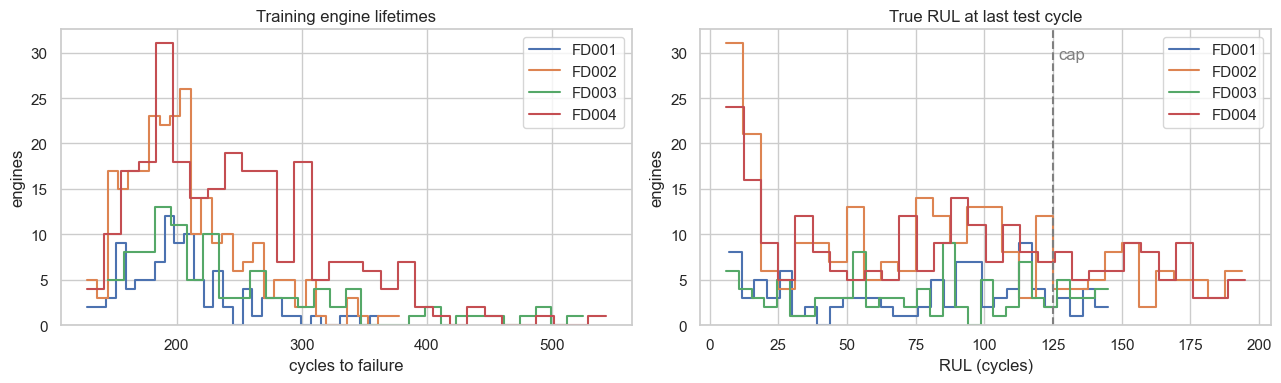

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, ds in data.items():
    sns.histplot(ds.train.groupby("unit")["cycle"].max(), ax=axes[0], label=name, element="step", fill=False, bins=30)
    sns.histplot(ds.test_rul, ax=axes[1], label=name, element="step", fill=False, bins=30)
axes[0].set(title="Training engine lifetimes", xlabel="cycles to failure", ylabel="engines")
axes[1].set(title="True RUL at last test cycle", xlabel="RUL (cycles)", ylabel="engines")
axes[1].axvline(RUL_CAP, ls="--", c="grey"); axes[1].text(RUL_CAP + 2, axes[1].get_ylim()[1] * 0.9, "cap", color="grey")
for ax in axes: ax.legend()
plt.tight_layout()

## 2. Operating conditions

FD001 and FD003 run at a single condition (sea level), so their operating settings are just noise. FD002 and FD004 have six conditions, which k-means on the three settings recovers cleanly.

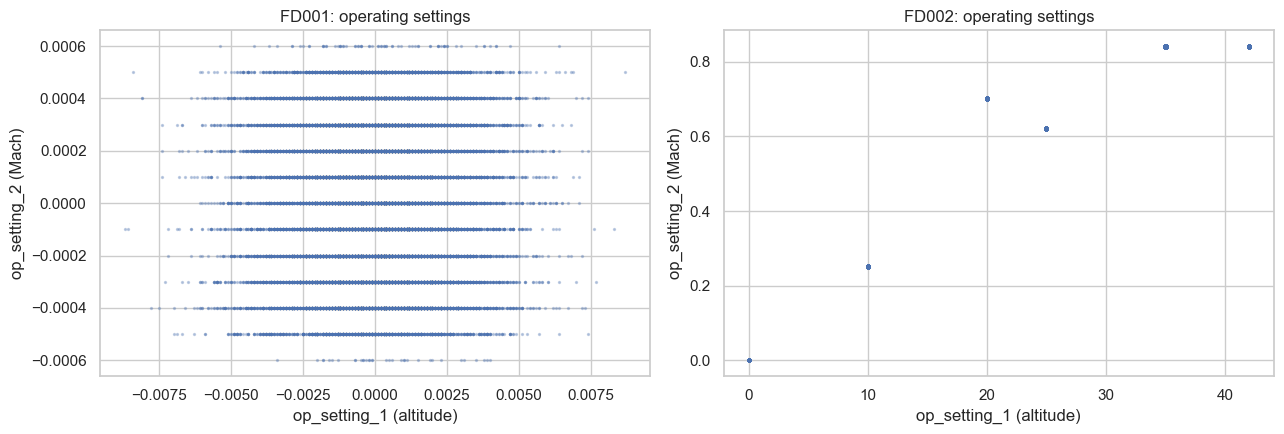

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, ["FD001", "FD002"]):
    tr = data[name].train
    ax.scatter(tr["op_setting_1"], tr["op_setting_2"], s=2, alpha=0.3)
    ax.set(title=f"{name}: operating settings", xlabel="op_setting_1 (altitude)", ylabel="op_setting_2 (Mach)")
plt.tight_layout()

In [5]:
def add_condition(df: pd.DataFrame, k: int, seed: int) -> pd.DataFrame:
    # EDA only: the production version (preprocess.py) fits k-means on training engines and reuses it for test.
    out = df.copy()
    out["condition"] = KMeans(k, n_init=10, random_state=seed).fit_predict(out[OP_SETTINGS]) if k > 1 else 0
    return out

def condition_zscore(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby("condition")[SENSORS]
    z = (df[SENSORS] - g.transform("mean")) / g.transform("std").replace(0, np.nan)
    return pd.concat([df.drop(columns=SENSORS), z], axis=1)

train = {name: add_condition(ds.train, N_CONDITIONS[name], cfg["seed"]) for name, ds in data.items()}
train_z = {name: condition_zscore(df) for name, df in train.items()}

for name in ["FD002", "FD004"]:
    centres = train[name].groupby("condition")[OP_SETTINGS].mean().round(3)
    centres["rows"] = train[name]["condition"].value_counts().sort_index()
    centres["within-cluster std (max)"] = train[name].groupby("condition")[OP_SETTINGS].std().max(axis=1).round(4)
    print(name); display(centres)

FD002


,op_setting_1,op_setting_2,op_setting_3,rows,within-cluster std (max)
condition,,,,,
0,4.20e+01,0.84,100.0,13458,2.90e-03
1,2.00e+01,0.70,100.0,8122,2.90e-03
2,2.50e+01,0.62,60.0,8002,2.90e-03
3,2.00e-03,0.00,100.0,8044,9.00e-04
4,1.00e+01,0.25,100.0,8096,2.90e-03
5,3.50e+01,0.84,100.0,8037,2.90e-03


FD004


,op_setting_1,op_setting_2,op_setting_3,rows,within-cluster std (max)
condition,,,,,
0,4.20e+01,0.84,100.0,15395,2.90e-03
1,1.00e+01,0.25,100.0,9224,2.90e-03
2,2.50e+01,0.62,60.0,9139,2.90e-03
3,2.00e+01,0.70,100.0,9091,2.90e-03
4,2.00e-03,0.00,100.0,9238,9.00e-04
5,3.50e+01,0.84,100.0,9162,2.90e-03


Clusters are tight (tiny within-cluster spread) and the centres are the same six flight conditions in FD002 and FD004. The plot below shows why this matters: in FD002 a raw sensor jumps between condition levels from cycle to cycle and hides the degradation trend, which only appears after normalising each sensor within its condition.

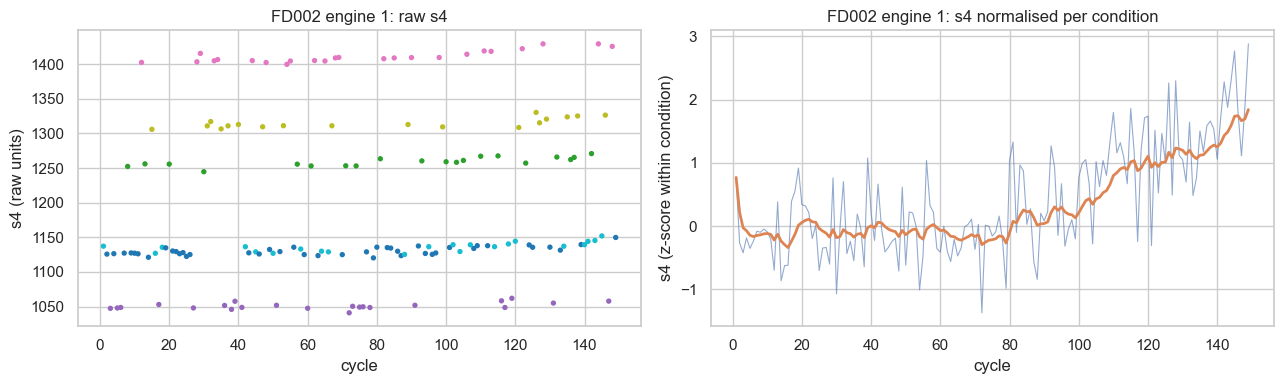

In [6]:
unit = 1
raw = train["FD002"].query("unit == @unit")
norm = train_z["FD002"].query("unit == @unit")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(raw["cycle"], raw["s4"], c=raw["condition"], cmap="tab10", s=8)
axes[0].set(title=f"FD002 engine {unit}: raw s4", xlabel="cycle", ylabel="s4 (raw units)")
axes[1].plot(norm["cycle"], norm["s4"], lw=0.8, alpha=0.6)
axes[1].plot(norm["cycle"], norm["s4"].ewm(span=15).mean(), lw=2)
axes[1].set(title=f"FD002 engine {unit}: s4 normalised per condition", xlabel="cycle", ylabel="s4 (z-score within condition)")
plt.tight_layout()

## 3. Sensor trends over engine life (FD001)

Each panel shows ten random training engines aligned at failure (x = cycles before failure, uncapped) plus the mean across all engines. Flat panels are sensors that carry no information.

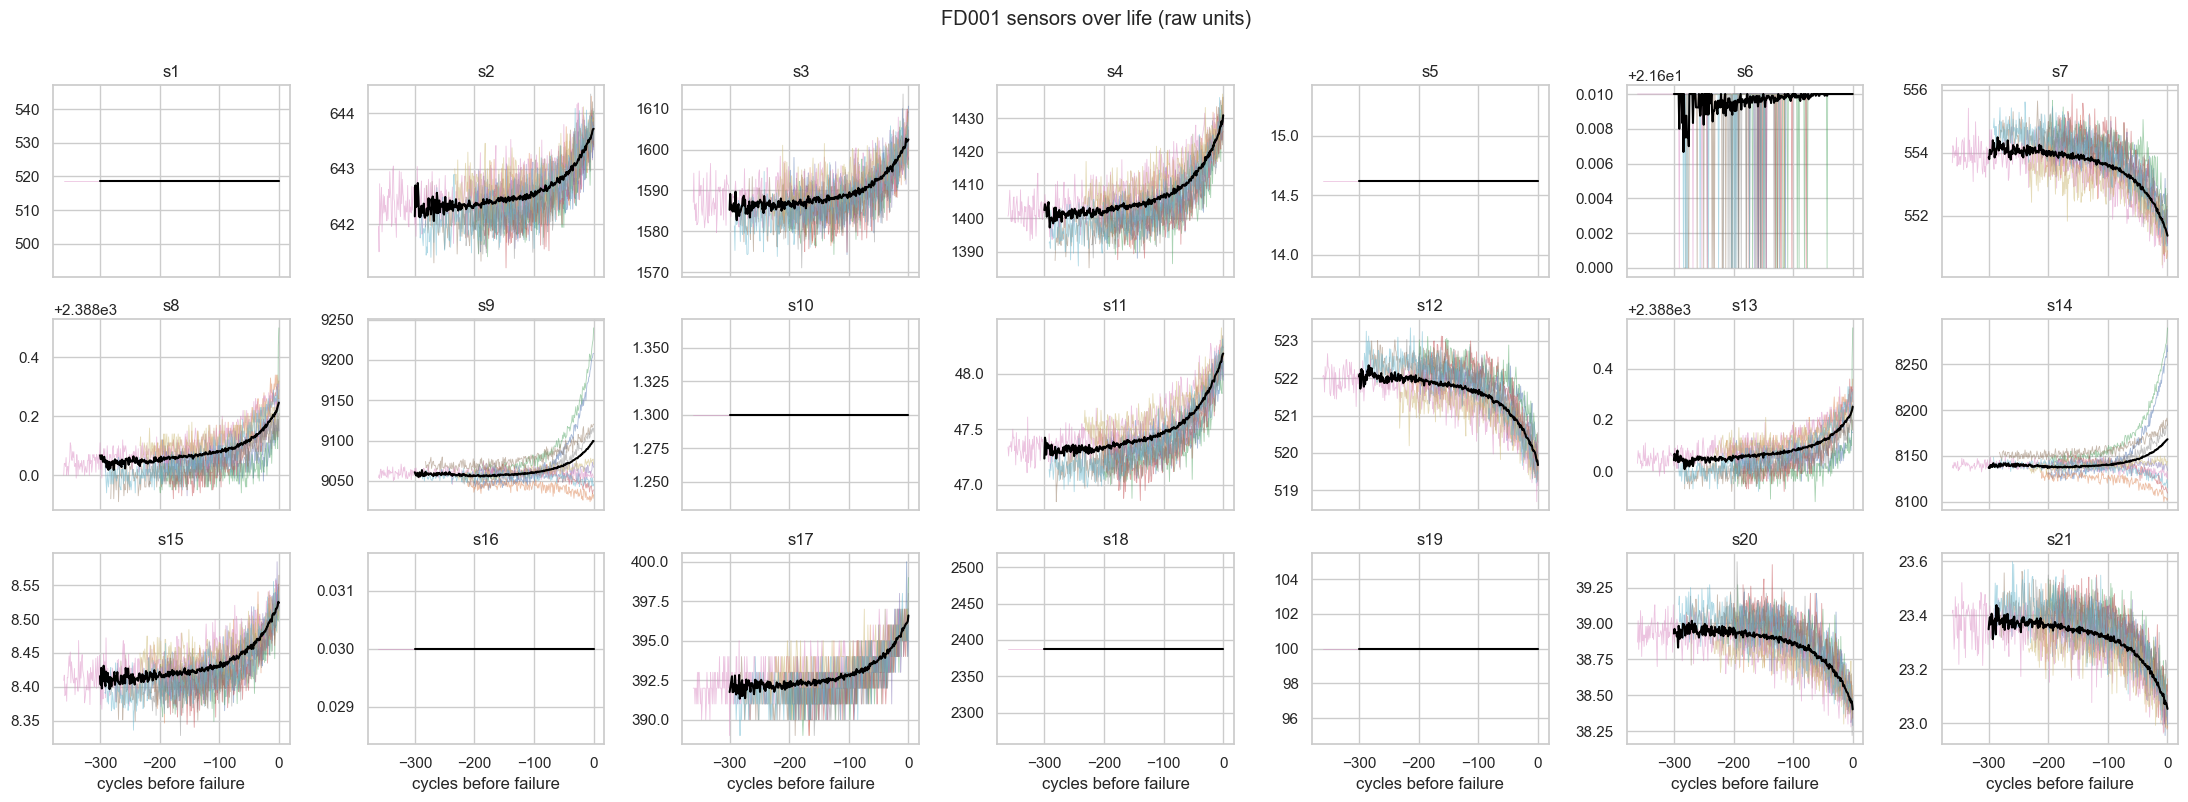

In [7]:
def plot_sensor_grid(df: pd.DataFrame, title: str, n_engines: int = 10) -> None:
    df = df.assign(to_failure=df["cycle"] - df.groupby("unit")["cycle"].transform("max"))
    units = RNG.choice(df["unit"].unique(), n_engines, replace=False)
    mean = df.groupby("to_failure")[SENSORS].mean().loc[-300:]
    fig, axes = plt.subplots(3, 7, figsize=(22, 8), sharex=True)
    for ax, s in zip(axes.flat, SENSORS):
        for u in units:
            e = df[df["unit"] == u]
            ax.plot(e["to_failure"], e[s], lw=0.6, alpha=0.5)
        ax.plot(mean.index, mean[s], c="black", lw=1.5)
        ax.set_title(s)
    for ax in axes[-1]: ax.set_xlabel("cycles before failure")
    fig.suptitle(title, y=1.0)
    plt.tight_layout()

plot_sensor_grid(train["FD001"], "FD001 sensors over life (raw units)")

Visibly flat in FD001: **s1, s5, s10, s16, s18, s19** (constant) and **s6** (two discrete values, no trend). The others drift steadily towards failure. **s9** and **s14** (core speed sensors) move in different directions for different engines, so their mean trend is weak even though each engine's trace is clear.

## 4. Fault modes push some sensors in opposite directions (FD003)

FD003 adds a fan-degradation fault. The plot shows the same sensors for engines split by whether s12 rises or falls over life — the two groups are the two fault modes. This is why a single global correlation with RUL **understates** these sensors, and it is a direct signal for the stretch goal FR-13 (fault classification).

engines by s12 direction: {-1.0: 56, 1.0: 44}


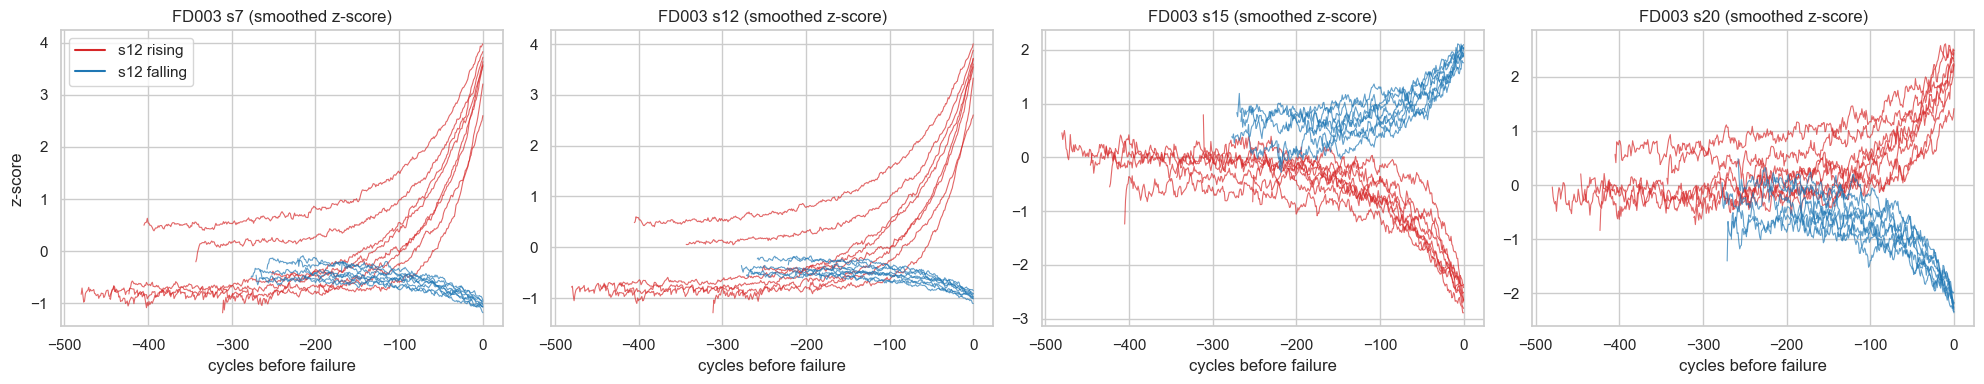

In [8]:
def engine_trend(df: pd.DataFrame) -> pd.DataFrame:
    # Spearman correlation of each sensor with cycle, computed per engine (NaN for constant sensors).
    def one(e: pd.DataFrame) -> pd.Series:
        return e[SENSORS].rank().corrwith(e["cycle"].rank())
    with np.errstate(invalid="ignore", divide="ignore"):
        return df.groupby("unit")[[*SENSORS, "cycle"]].apply(one)

fd3 = train_z["FD003"].assign(to_failure=lambda d: d["cycle"] - d.groupby("unit")["cycle"].transform("max"))
direction = np.sign(engine_trend(fd3)["s12"])
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharex=True)
for ax, s in zip(axes, ["s7", "s12", "s15", "s20"]):
    for sign, colour in [(1, "tab:red"), (-1, "tab:blue")]:
        for u in direction[direction == sign].index[:8]:
            e = fd3[fd3["unit"] == u]
            ax.plot(e["to_failure"], e[s].ewm(span=10).mean(), c=colour, lw=0.8, alpha=0.7)
    ax.set(title=f"FD003 {s} (smoothed z-score)", xlabel="cycles before failure")
axes[0].set_ylabel("z-score"); axes[0].plot([], [], c="tab:red", label="s12 rising"); axes[0].plot([], [], c="tab:blue", label="s12 falling"); axes[0].legend()
plt.tight_layout()
print("engines by s12 direction:", direction.value_counts().to_dict())

## 5. Which sensors carry degradation signal?

For every subset (after per-condition normalisation) two measures per sensor, both from training engines only:

- **trend strength**: mean over engines of |Spearman ρ(sensor, cycle)| within each engine. Robust to sensors that move in opposite directions in different engines. NaN = constant within every condition.
- **direction agreement**: |mean sign| of those per-engine correlations. 1 = every engine trends the same way; near 0 = split directions (fault modes, or non-monotonic sensors such as s9/s14).

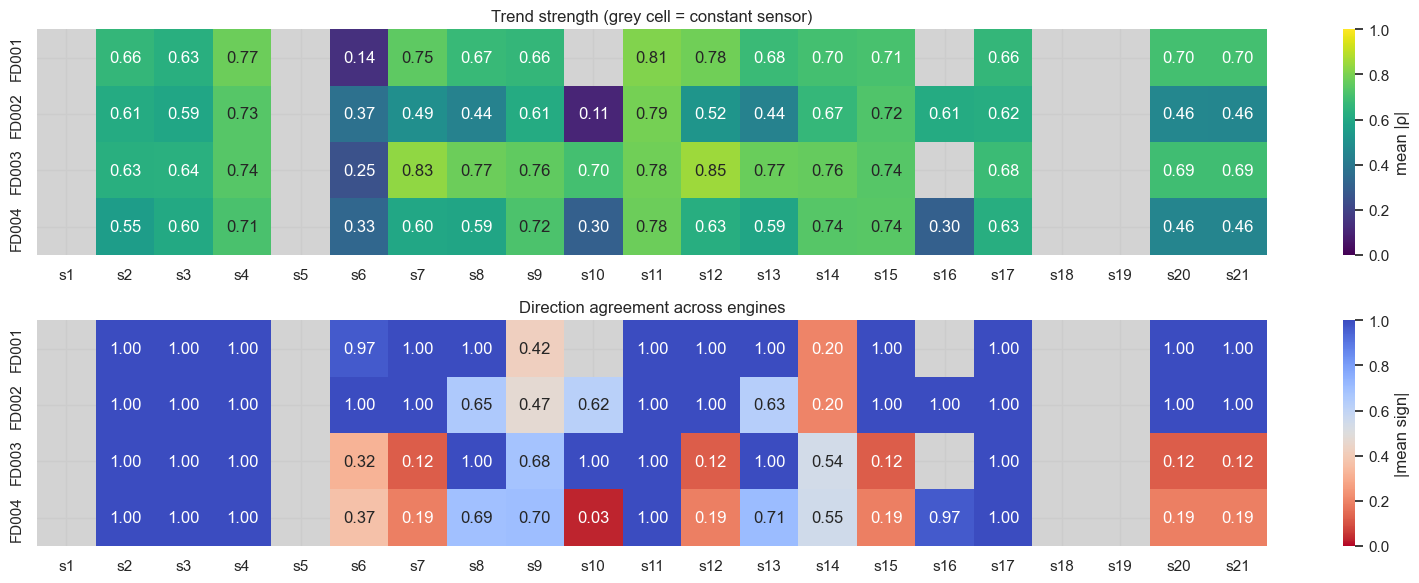

In [9]:
trends = {name: engine_trend(df) for name, df in train_z.items()}
strength = pd.DataFrame({n: t.abs().mean() for n, t in trends.items()}).T
agreement = pd.DataFrame({n: np.sign(t).mean().abs() for n, t in trends.items()}).T

fig, axes = plt.subplots(2, 1, figsize=(16, 6))
sns.heatmap(strength, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "mean |ρ|"})
axes[0].set_title("Trend strength (grey cell = constant sensor)")
sns.heatmap(agreement, annot=True, fmt=".2f", cmap="coolwarm_r", vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "|mean sign|"})
axes[1].set_title("Direction agreement across engines")
for ax in axes: ax.set_facecolor("lightgrey")
plt.tight_layout()

For comparison, the usual global Spearman correlation with capped RUL — raw versus per-condition normalised. In FD002/FD004 the raw correlations are near zero for every sensor; normalisation within condition recovers them. In FD003, the opposite-direction sensors (s7, s12, s15, s20, s21) look useless by this measure despite strong per-engine trends.

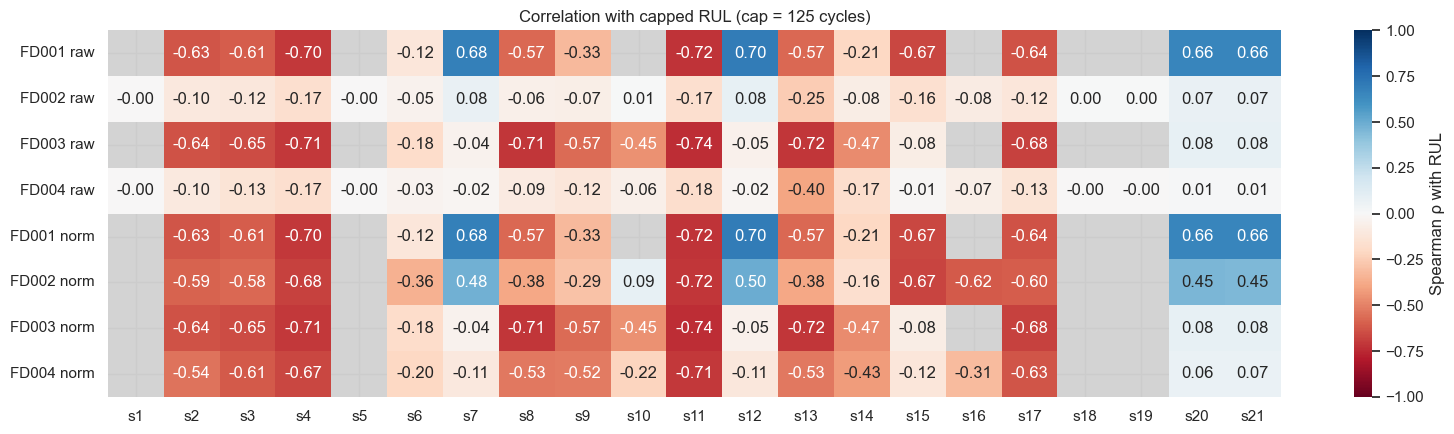

In [10]:
def rul_corr(df: pd.DataFrame) -> pd.Series:
    return df[SENSORS].corrwith(df["rul"], method="spearman")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # constant sensors have undefined correlation (shown as grey)
    corr = pd.DataFrame({
        **{f"{n} raw": rul_corr(ds.train) for n, ds in data.items()},
        **{f"{n} norm": rul_corr(train_z[n]) for n in SUBSETS},
    }).T
fig, ax = plt.subplots(figsize=(16, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman ρ with RUL"})
ax.set_facecolor("lightgrey"); ax.set_title(f"Correlation with capped RUL (cap = {RUL_CAP} cycles)")
plt.tight_layout()

## 6. Correlations between sensors (FD001)

Many sensors are strongly correlated — they measure the same underlying degradation from different places in the engine. That is harmless for trees and neural nets but makes linear-model coefficients unstable, and means SHAP credit will be shared across correlated sensors (worth noting when explaining predictions).

Pairs with |r| > 0.9:
s9  s14    0.96


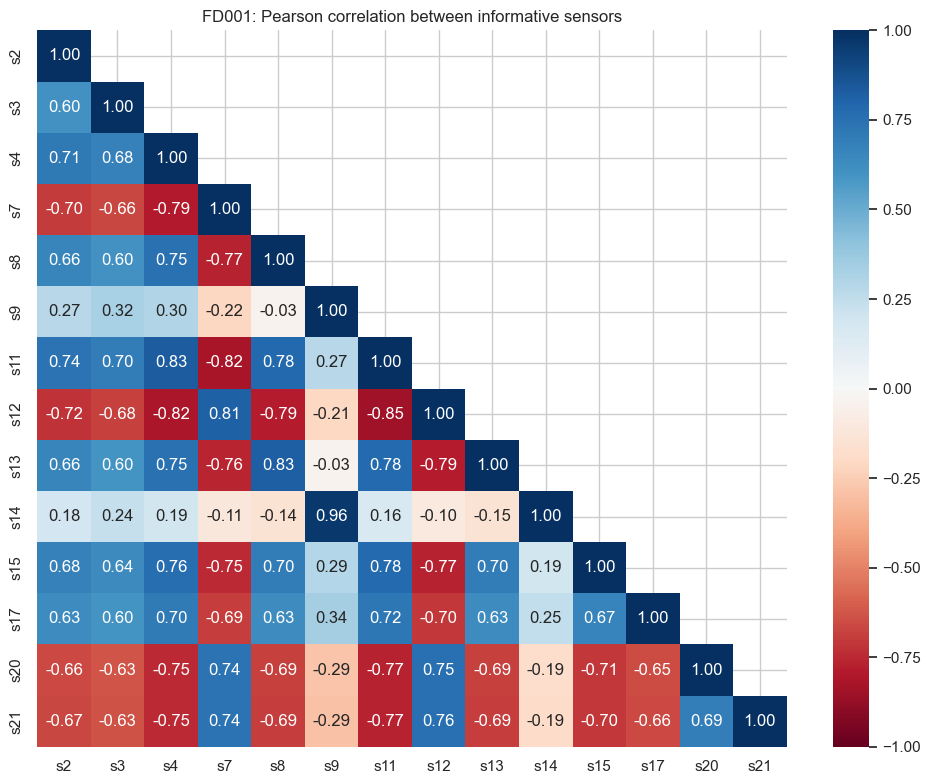

In [11]:
informative = strength.loc["FD001"].dropna().index[strength.loc["FD001"].dropna() >= 0.2]
c = train["FD001"][informative].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=ax, mask=np.triu(np.ones_like(c, dtype=bool), k=1))
ax.set_title("FD001: Pearson correlation between informative sensors")
plt.tight_layout()

pairs = c.where(np.triu(np.ones_like(c, dtype=bool), k=1)).stack()
print("Pairs with |r| > 0.9:"); print(pairs[pairs.abs() > 0.9].round(3).to_string())

## 7. Conclusions: sensors to drop

**Rule** (to be implemented in `preprocess.py`, Phase 2, with the threshold in config): drop a sensor if it is constant within every operating condition, or if its trend strength (mean per-engine |ρ| with cycle) is below **0.2**. Trend strength is used instead of global correlation with RUL because it does not penalise sensors that degrade in opposite directions under different fault modes.

In [12]:
THRESHOLD = 0.2
selection = pd.DataFrame({
    "drop": [", ".join(s for s in SENSORS if not strength.loc[n, s] >= THRESHOLD) for n in SUBSETS],
    "kept": [int((strength.loc[n] >= THRESHOLD).sum()) for n in SUBSETS],
    "weak but kept (0.2–0.4)": [", ".join(s for s in SENSORS if 0.2 <= strength.loc[n, s] < 0.4) for n in SUBSETS],
}, index=pd.Index(SUBSETS, name="subset"))
selection

,drop,kept,weak but kept (0.2–0.4)
subset,,,
FD001,"s1, s5, s6, s10, s16, s18, s19",14,
FD002,"s1, s5, s10, s18, s19",16,s6
FD003,"s1, s5, s16, s18, s19",16,s6
FD004,"s1, s5, s18, s19",17,"s6, s10, s16"


**Findings**

1. **FD001: drop s1, s5, s6, s10, s16, s18, s19 and keep 14 sensors.** This is the selection most published C-MAPSS work uses.
2. **The four subsets disagree, so selection should be per subset, not a hard-coded list.**
   - s10 is flat in FD001 but carries strong signal in FD003, where it is fan-fault related.
   - s16 matters in FD002.
   - s1, s5, s18 and s19 never carry signal.
3. **Per-condition normalisation is essential for FD002 and FD004.** Without it, every sensor's correlation with RUL is near zero (PRD §6 step 2).
4. **In FD003 and FD004, some sensors (s7, s12, s15, s20, s21) move in opposite directions depending on the fault mode.**
   - Models need per-engine trend features such as slope, not just levels.
   - The same sensors give an easy signal for fault classification (FR-13).
5. **Many sensors are strongly correlated with each other.** s9 and s14 are near-duplicates (r = 0.96), and most other informative sensors pair at |r| ≈ 0.6–0.85. Expect linear-model coefficients and SHAP credit to be spread across these groups.
6. **Some FD002 and FD004 test engines have fewer than 30 cycles of history**, so the windowing step must pad them.